In [1]:
import numpy as np 
from pathlib import Path 
from load_file import load_file

file_path = Path(r"C:\Users\arni-experiment\Documents\K.Boykin\SDR_PROJECT\rtl-sdr-64bit-20260906\aprs3.bin")

samples = (load_file(file_path))

# Original sample rate 
fs = 2_048_000  # sampling freq 

print("Original IQ samples:", len(samples))
print("Original sample rate:", fs, "samples/sec") 
print("Recording duration:", len(samples) / fs, "seconds")

Original IQ samples: 41920000
Original sample rate: 2048000 samples/sec
Recording duration: 20.46875 seconds


Output samples: 655000
Output sample rate: 32000 samples/sec
Recording duration: 20.46875 seconds


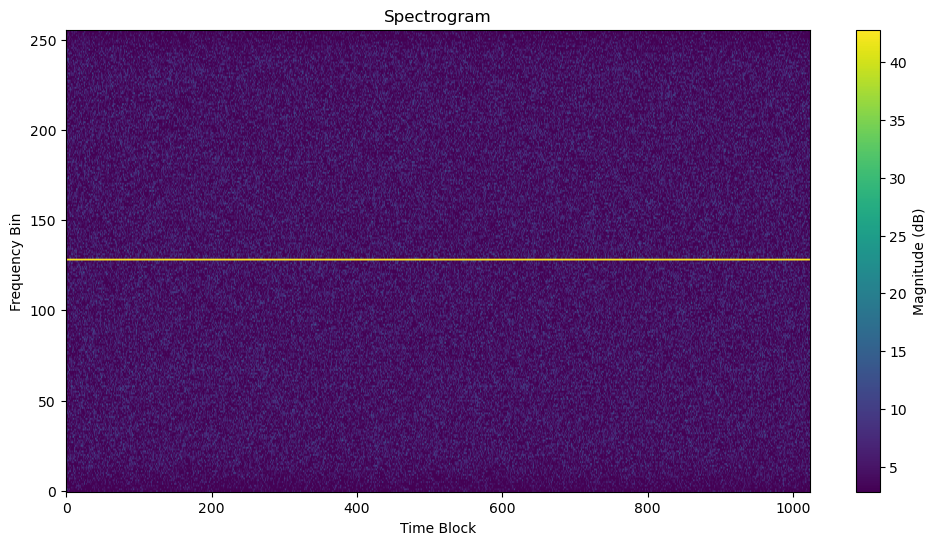

C:\Users\arni-experiment\anaconda3\envs\torch_cuda\lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
C:\Users\arni-experiment\anaconda3\envs\torch_cuda\lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


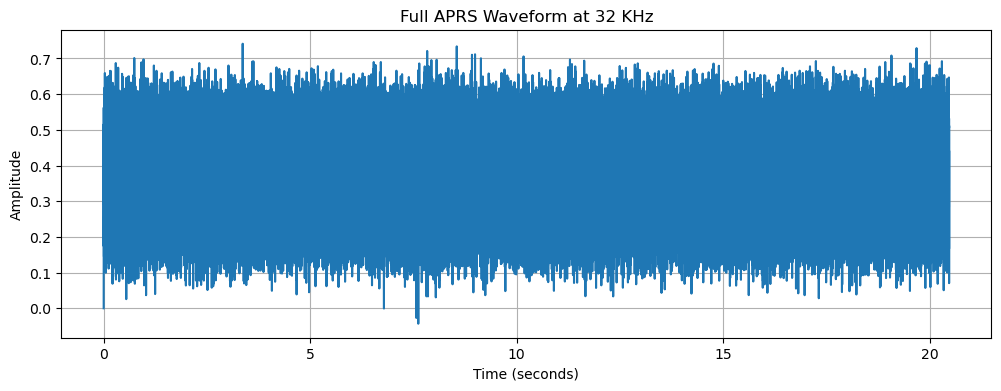

In [2]:
from scipy.signal import decimate 
from msg import msg 
import matplotlib.pyplot as plt 

# Decimate at a factor of 64 to 32 kHz
d = decimate(samples, 8, ftype="fir")
dd = decimate(d, 8, ftype="fir")

dd [0] = 0

print("Output samples:", len(dd))
print("Output sample rate:", 32000, "samples/sec")
print("Recording duration:", len(dd) / 32000, "seconds")

spectrogram = msg(dd, 1, 256, 1024)

# full waveform 
fs2 = 32000  # Sample rate after resampling

time = np.arange(len(dd)) / fs2

plt.figure(figsize=(12, 4))
plt.plot(time, dd)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Full APRS Waveform at 32 KHz")
plt.grid(True)
plt.show()


In [3]:
# Process to extract first APRS packet 

# Extract 16,384 samples 
dp = dd[380000:380000 + 16384].copy()

# Remove the mean (DC offset) from selected samples 
dp = dp - np.sum(dp) / len(dp)


print("Number of samples:", len(dp))
print("Mean after removal:", np.mean(dp))


Number of samples: 16384
Mean after removal: (2.3771132631744685e-17+1.5395670849294163e-17j)


In [4]:
from scipy import signal

# dp = dp - np.mean(dp)

data = signal.resample_poly(dp, 3, 4)

fs = 24000  # New sample rate in samples/sec
baud_rate = 1200

print("Original samples:", len(dp))
print("Resampled samples:", len(data))
print("New sample rate:", fs, "samples/sec")
print("Samples per bit:", fs // baud_rate)
print("Resampled duration:", len(data) / fs, "seconds")

dpfreq = np.angle(
    np.conj(data[:-1]) * data[1:]
)

print("Demodulated samples:", len(dpfreq))



Original samples: 16384
Resampled samples: 12288
New sample rate: 24000 samples/sec
Samples per bit: 20
Resampled duration: 0.512 seconds
Demodulated samples: 12287


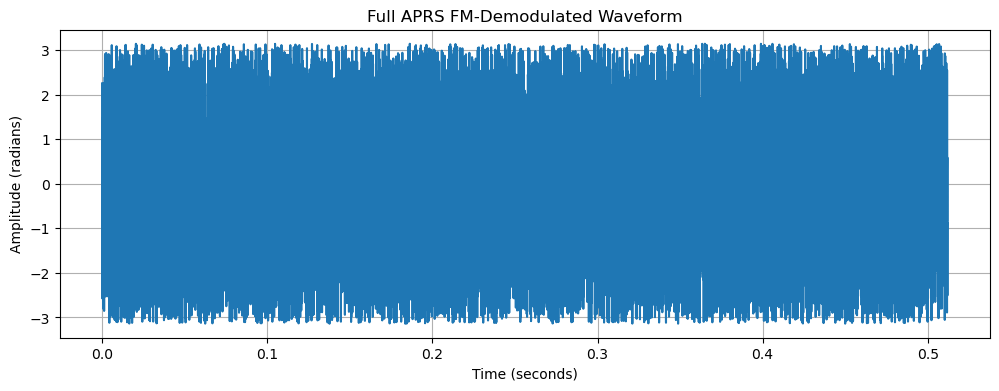

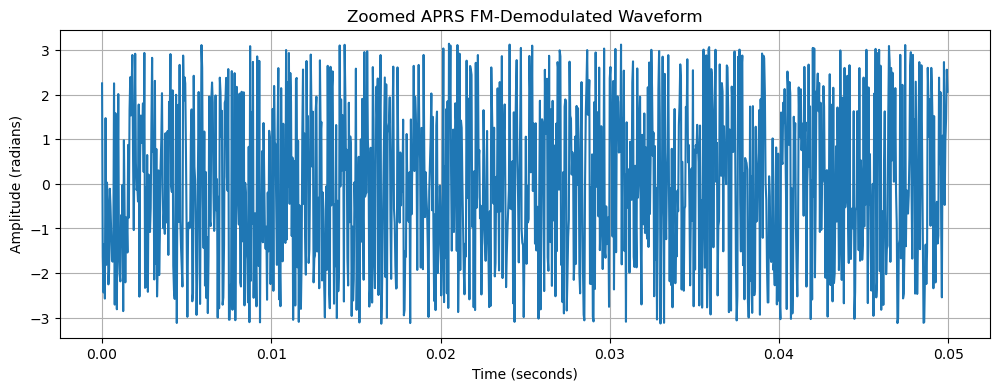

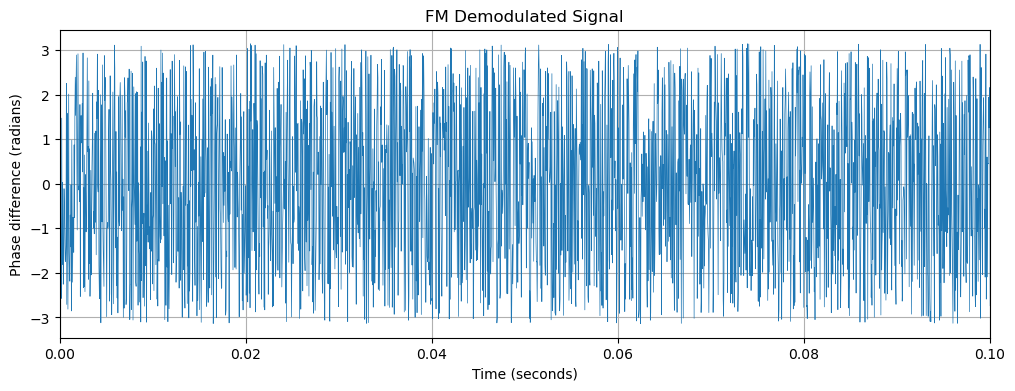

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# full waveform 
fs = 24000  # Sample rate after resampling

time = np.arange(len(dpfreq)) / fs

plt.figure(figsize=(12, 4))
plt.plot(time, dpfreq)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (radians)")
plt.title("Full APRS FM-Demodulated Waveform")
plt.grid(True)
plt.show()


# zoomed in waveform First 0.05 seconds
n = 1200  

plt.figure(figsize=(12, 4))
plt.plot(np.arange(n) / fs, dpfreq[:n])
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (radians)")
plt.title("Zoomed APRS FM-Demodulated Waveform")
plt.grid(True)
plt.show()


# zoomed view of the first 0.1 seconds 
t = np.arange(len(dpfreq)) / fs

plt.figure(figsize=(12, 4))
plt.plot(t, dpfreq, linewidth=0.5)
plt.xlabel("Time (seconds)")
plt.ylabel("Phase difference (radians)")
plt.title("FM Demodulated Signal")
plt.grid(True)
plt.xlim(0, 0.1)
plt.show()

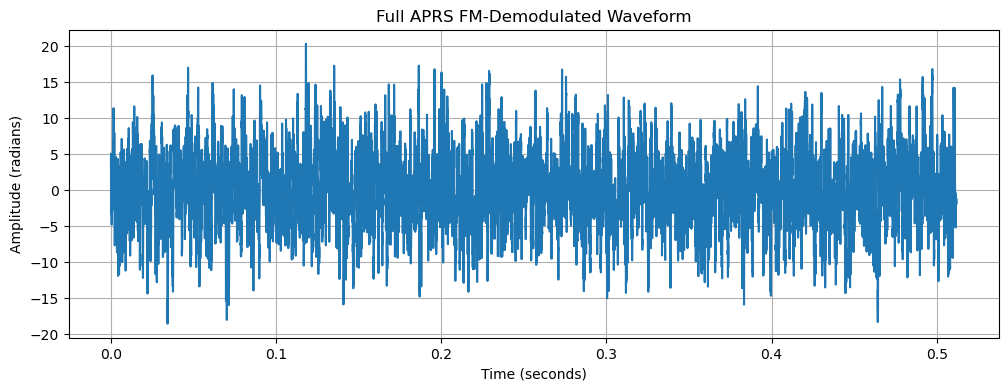

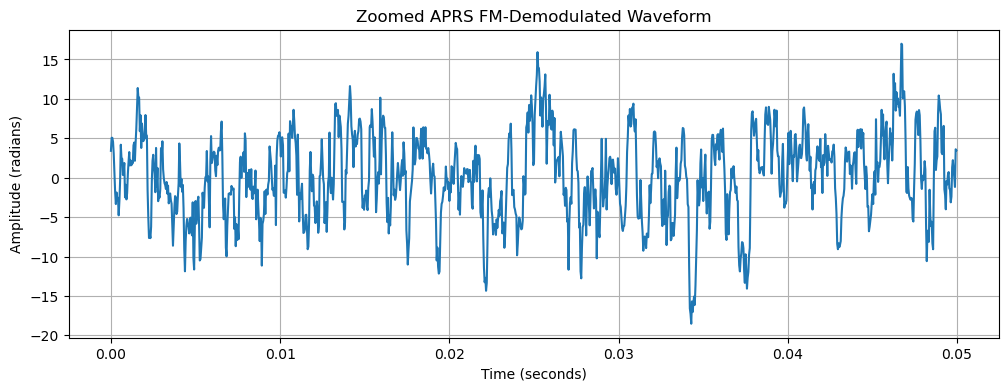

In [7]:
# Create the time array fom -10 to 9, divided by 20 

# One cycle over 20 samples: 1200 Hz bit
t20 = np.arange(-10, 10) / 20

mf1200 = np.exp(1j * 2 * np.pi * t20 * 1.0)

# 1.8 cycles over 20 samples: 2200 Hz bit
mf2200 = np.exp(1j * 2 * np.pi * t20 * 1.8)


#Perform convolution with the 'same' mode 
d12 = np.convolve(dpfreq, mf1200, mode='same') 

d22 = np.convolve(dpfreq, mf2200, mode='same') 

# Calculate the difference of absolute values (magnitudes) 

ddif = np.abs(d12) - np.abs(d22) 


# full waveform 
fs = 24000  # Sample rate after resampling

time = np.arange(len(dpfreq)) / fs

plt.figure(figsize=(12, 4))
plt.plot(time, ddif)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (radians)")
plt.title("Full APRS FM-Demodulated Waveform")
plt.grid(True)
plt.show()


# zoomed in waveform 
n = 1200  # First 0.05 seconds

plt.figure(figsize=(12, 4))
plt.plot(np.arange(n) / fs, ddif[:n])
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (radians)")
plt.title("Zoomed APRS FM-Demodulated Waveform")
plt.grid(True)
plt.show()

Samples selected: 5120


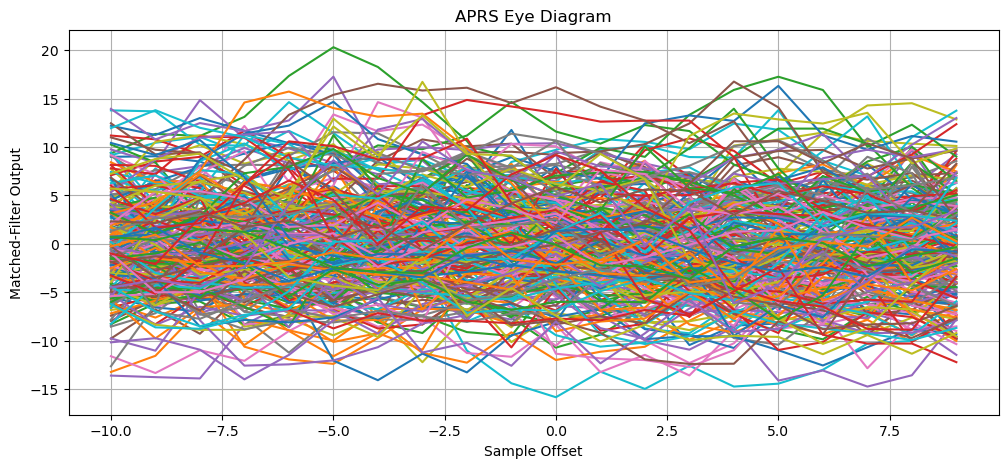

In [8]:
import numpy as np
import matplotlib.pyplot as plt


n1 = 2000
n2 = n1 + 20 * 256 - 1


# centered around each bit
boff = np.arange(-10, 10)

# Extract samples and reshape into 256 segments of 20 samples
eyed = ddif[(n1 - 1 -10):(n2 - 10)].reshape(20, 256, order="F")

print("Samples selected:", eyed.size)

# Plot the eye diagram
plt.figure(figsize=(12, 5))
plt.plot(boff, eyed)
plt.xlabel("Sample Offset")
plt.ylabel("Matched-Filter Output")
plt.title("APRS Eye Diagram")
plt.grid(True)
plt.show()

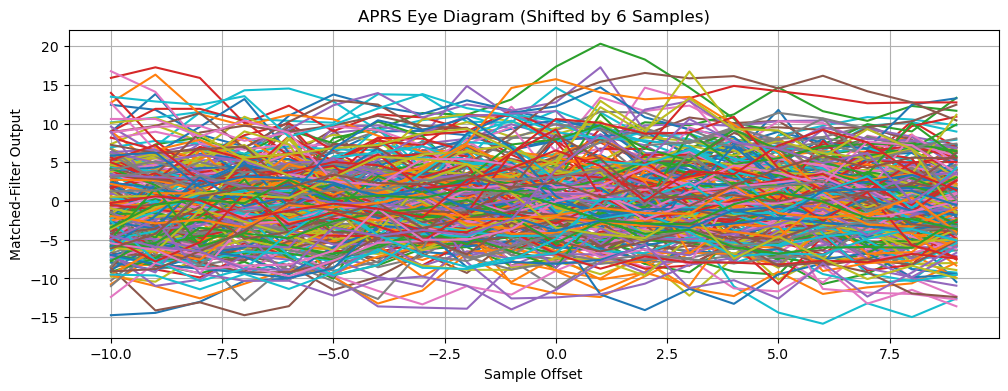

In [9]:
# Shift the selected samples by 6 samples
eyedm6 = ddif[(n1 - 17):(n2 - 16)].reshape(20, 256, order="F")

# Plot the shifted eye diagram
plt.figure(figsize=(12, 4))
plt.plot(boff, eyedm6)
plt.xlabel("Sample Offset")
plt.ylabel("Matched-Filter Output")
plt.title("APRS Eye Diagram (Shifted by 6 Samples)")
plt.grid(True)
plt.show()

Samples selected: 1000


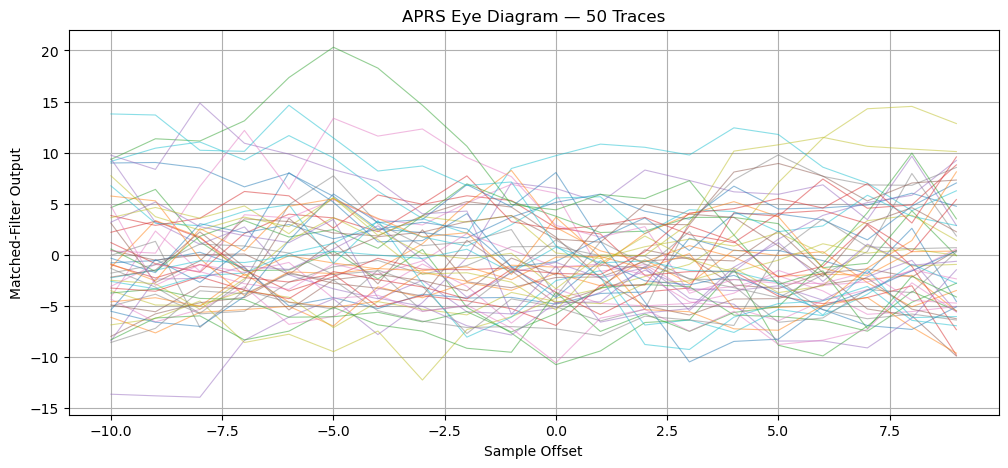

In [10]:
n1 = 2000
num_traces = 50

n2 = n1 + 20 * num_traces - 1

# Centered around each bit
boff = np.arange(-10, 10)

# Extract samples and reshape into 100 segments of 20 samples
eyed = ddif[
    (n1 - 1 - 10):(n1 - 1 - 10 + 20 * num_traces)
].reshape(20, num_traces, order="F")

print("Samples selected:", eyed.size)

plt.figure(figsize=(12, 5))
plt.plot(boff, eyed, linewidth=0.8, alpha=0.5)
plt.xlabel("Sample Offset")
plt.ylabel("Matched-Filter Output")
plt.title("APRS Eye Diagram — 50 Traces")
plt.grid(True)
plt.show()

Samples selected: 1000


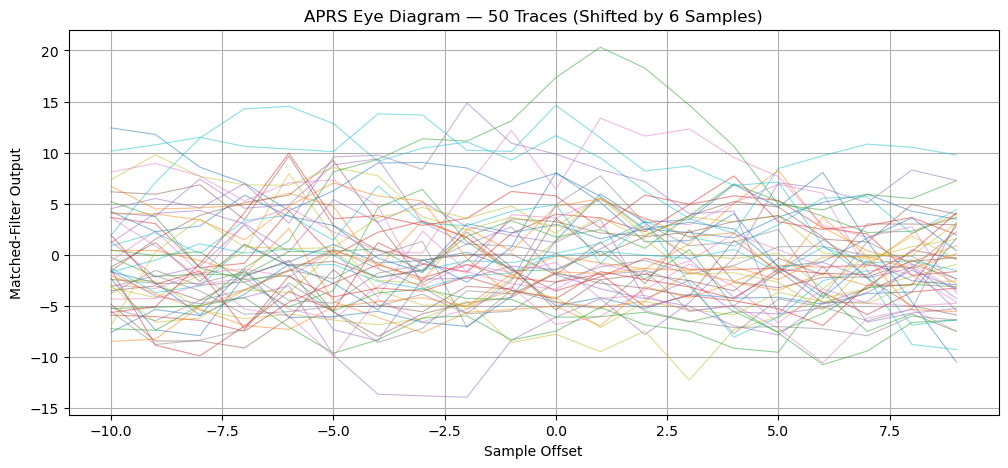

In [11]:

n1 = 2000
num_traces = 50

n2 = n1 + 20 * num_traces - 1

# Centered around each bit
boff = np.arange(-10, 10)

# Shift the eye diagram by 6 samples
eyedm6 = ddif[
    (n1 - 17):(n1 - 17 + 20 * num_traces)
].reshape(20, num_traces, order="F")

print("Samples selected:", eyedm6.size)

# Plot the shifted eye diagram
plt.figure(figsize=(12, 5))
plt.plot(boff, eyedm6, linewidth=0.8, alpha=0.5)
plt.xlabel("Sample Offset")
plt.ylabel("Matched-Filter Output")
plt.title("APRS Eye Diagram — 50 Traces (Shifted by 6 Samples)")
plt.grid(True)
plt.show()


In [12]:
# # Sample once every 20 samples, starting at index -7

# Sample every 20 samples, starting at index 13
bts = ddif[13::20] > 0

print("Number of sampled bits:", len(bts))
print("First 20 bits:", bts[:20].astype(int))

print("Length of ddif:", len(ddif))
print("Expected bits for 10 seconds:", 10 * 1200)
print("Actual bit decisions:", len(bts))

print("Original dp:", len(dp))
print("Resampled data:", len(data))
print("FM demodulated dpfreq:", len(dpfreq))
print("Tone difference ddif:", len(ddif))

Number of sampled bits: 614
First 20 bits: [0 1 0 1 0 0 0 1 0 1 0 1 1 0 0 0 1 1 1 0]
Length of ddif: 12287
Expected bits for 10 seconds: 12000
Actual bit decisions: 614
Original dp: 16384
Resampled data: 12288
FM demodulated dpfreq: 12287
Tone difference ddif: 12287


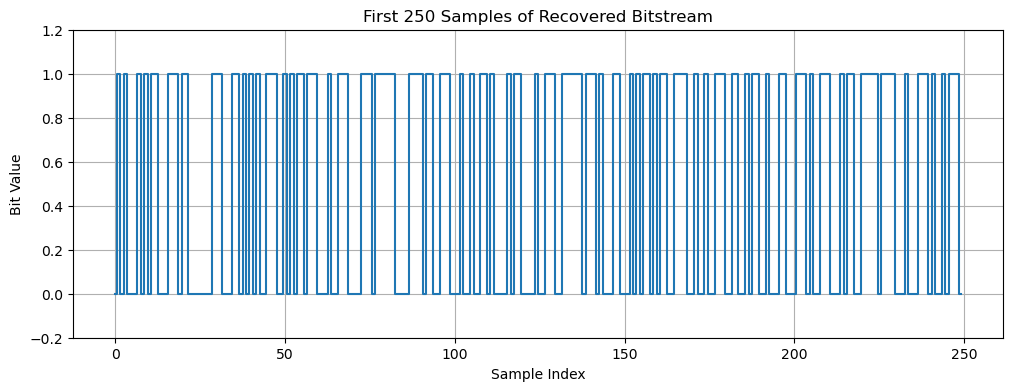

In [13]:
import matplotlib.pyplot as plt

# Select the first 250 bits and convert Boolean values to integers
bts_plot = bts[:250].astype(int)

# Plot the bitstream as a step function
plt.figure(figsize=(12, 4))
plt.step(range(len(bts_plot)), bts_plot, where="mid")

plt.xlabel("Sample Index")
plt.ylabel("Bit Value")
plt.title("First 250 Samples of Recovered Bitstream")
plt.grid(True)
plt.ylim(-0.2, 1.2)
plt.show()

Input tone decisions: 614
NRZI-decoded bits: 614
First 80 decoded bits:
[1 0 0 0 0 1 1 0 0 0 0 0 1 0 1 1 0 1 1 0 0 1 0 1 1 1 1 1 1 0 1 1 0 1 1 0 1
 0 0 0 0 0 0 0 1 0 1 1 0 1 0 0 0 0 0 1 0 0 1 1 0 1 1 0 0 1 0 1 1 0 1 1 1 0
 1 1 0 0 1 1]


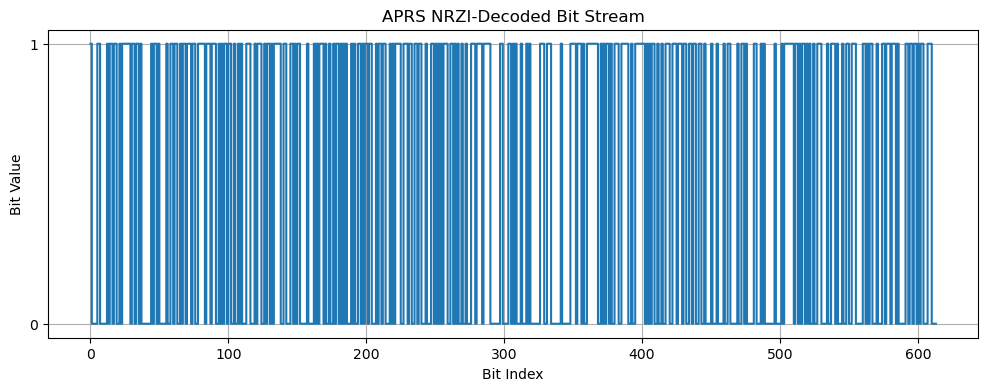

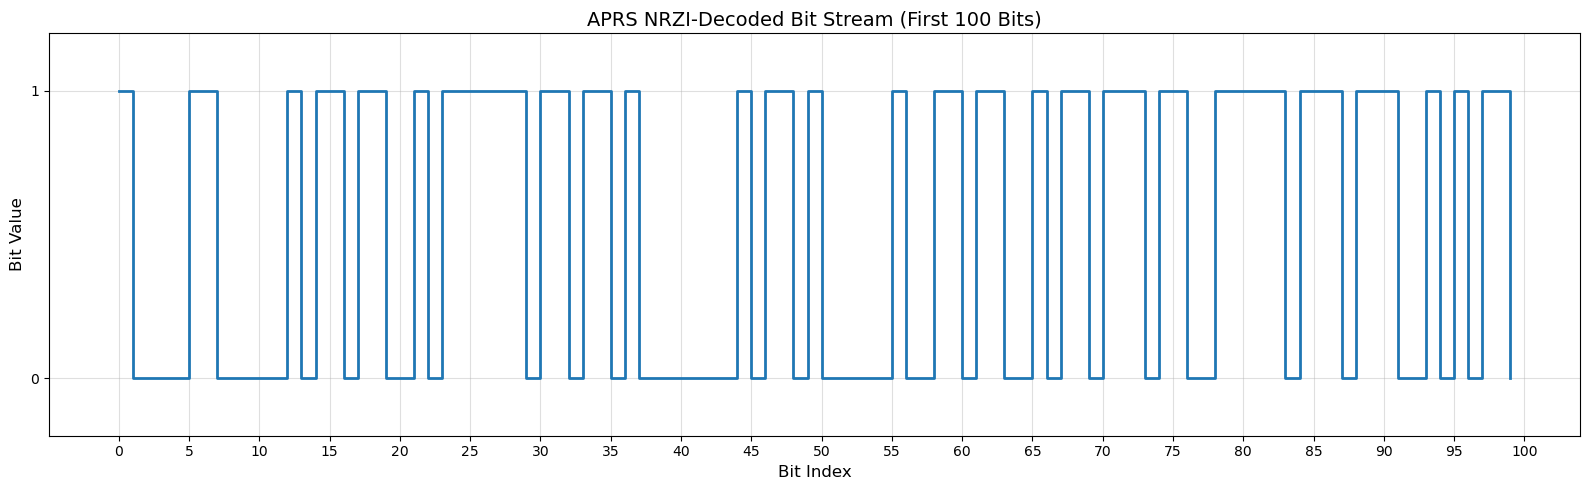

In [14]:
from decode_aprs import decode_NRZI

db = decode_NRZI(bts)

print("Input tone decisions:", len(bts))
print("NRZI-decoded bits:", len(db))
print("First 80 decoded bits:")
print(db[:80])

plt.figure(figsize=(12, 4))
plt.step(np.arange(len(db)), db, where="post")
plt.xlabel("Bit Index")
plt.ylabel("Bit Value")
plt.title("APRS NRZI-Decoded Bit Stream")
plt.yticks([0, 1])
plt.grid(True)
plt.show()

# Plot the first 100 bits with more horizontal spacing
num_bits = 100
bits = db[:num_bits]

plt.figure(figsize=(16, 5))
plt.step(np.arange(len(bits)), bits, where="post", linewidth=2)

plt.xlabel("Bit Index", fontsize=12)
plt.ylabel("Bit Value", fontsize=12)
plt.title("APRS NRZI-Decoded Bit Stream (First 100 Bits)", fontsize=14)

plt.xticks(np.arange(0, num_bits + 1, 5))
plt.yticks([0, 1])
plt.ylim(-0.2, 1.2)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

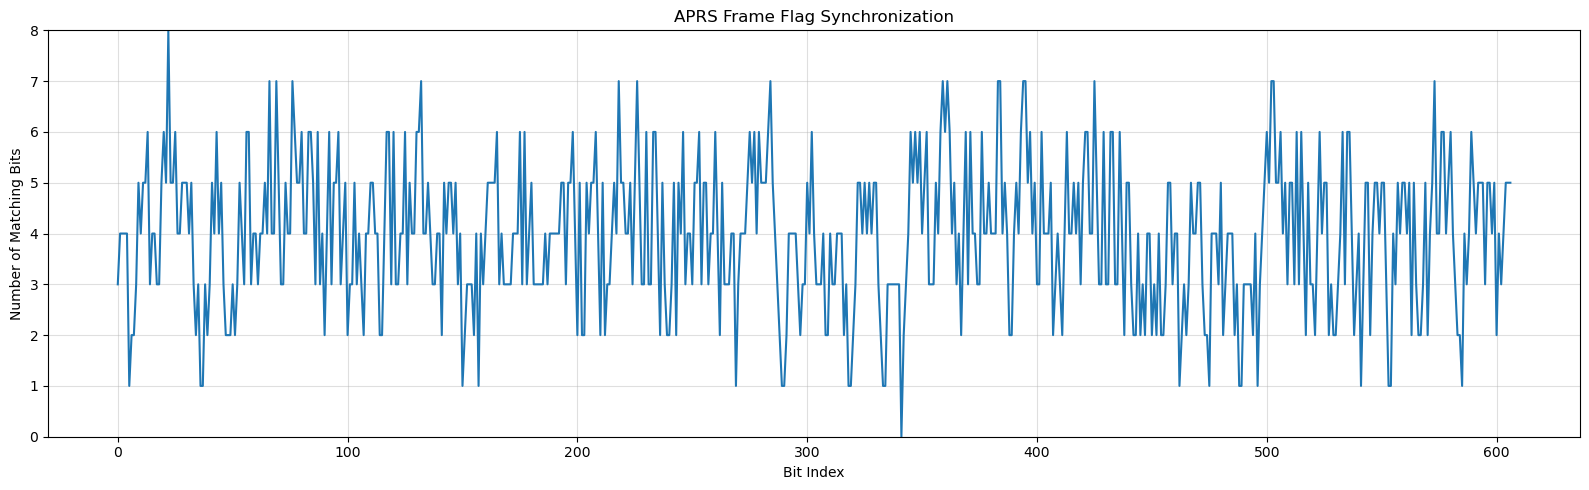

In [15]:
# APRS frame flag after NRZI decoding
fb = np.array([0, 1, 1, 1, 1, 1, 1, 0])

# Count matching bits in each 8-bit window
matches = np.array([
    np.sum(~np.logical_xor(db[kk:kk+8], fb))
    for kk in range(len(db) - 7)
])

plt.figure(figsize=(16, 5))
plt.plot(matches, linewidth=1.5)

plt.xlabel("Bit Index")
plt.ylabel("Number of Matching Bits")
plt.title("APRS Frame Flag Synchronization")
plt.yticks(np.arange(0, 9, 1))
plt.ylim(0, 8)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


In [16]:
from decode_aprs import frame_byte_sync

# Stage 2: Find frame flags
dbs = frame_byte_sync(db)

print("Bits after leading frame flags:", len(dbs))
print(dbs[:80])


First frame flag starts at bit: 22
Leading frame flags found: 1
Bits after leading frame flags: 584
[1 1 0 1 1 0 1 0 0 0 0 0 0 0 1 0 1 1 0 1 0 0 0 0 0 1 0 0 1 1 0 1 1 0 0 1 0
 1 1 0 1 1 1 0 1 1 0 0 1 1 1 1 1 0 1 1 1 0 1 1 1 0 0 1 0 1 0 1 1 0 1 1 0 0
 1 0 0 1 0 1]


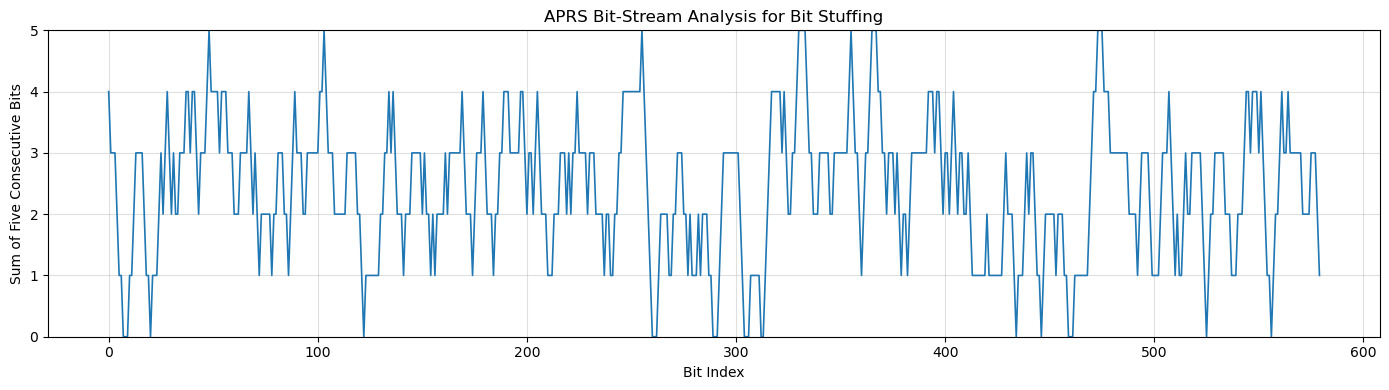

Bits before de-stuffing: 584
Bits after de-stuffing: 580
Bits removed: 4


In [17]:

from decode_aprs import de_bit_stuff

# Visualize sums over five consecutive bits
conv = np.convolve(dbs, np.ones(5, dtype=int), mode="valid")

plt.figure(figsize=(14, 4))
plt.plot(conv, linewidth=1.2)
plt.xlabel("Bit Index")
plt.ylabel("Sum of Five Consecutive Bits")
plt.title("APRS Bit-Stream Analysis for Bit Stuffing")
plt.yticks(np.arange(0, 6, 1))
plt.ylim(0, 5)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

# Remove bit stuffing
dbsd = de_bit_stuff(dbs)

print("Bits before de-stuffing:", len(dbs))
print("Bits after de-stuffing:", len(dbsd))
print("Bits removed:", len(dbs) - len(dbsd))


In [18]:
from decode_aprs import bits_to_char

cs = bits_to_char(dbsd)

print("Decoded APRS packet:")
print(repr(cs))

Decoded APRS packet:
'[@\x0b²i7ÿNmR\x1c\x9dÖ7Ö Ô%\xad¢¬\x8d6ê¹Ù\x88Ug%qï\x03Ã\x8a(à\x1c\x10x\x97\x7fj9_þj\x92s7\x9b\t\x112È\x82Q@èo\xadä\x90\x8bÌÁ\x1a±»`[ã'
